# **1. Import modules**

In [1]:
from sklearn import datasets
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification

from sklearn.model_selection import cross_val_score

# 2.  **Import Data**

In [2]:
import numpy as np 
import pandas as pd 

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/math482-2024-2025-1-hw-02-v2/sample_submission.csv
/kaggle/input/math482-2024-2025-1-hw-02-v2/train.csv
/kaggle/input/math482-2024-2025-1-hw-02-v2/test.csv


In [3]:
df = pd.read_csv("/kaggle/input/math482-2024-2025-1-hw-02-v2/train.csv")
df.head(-1)

,id,feature_01,feature_02,feature_03,feature_04,feature_05,feature_06,feature_07,feature_08,feature_09,...,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,target
0,1,262.108596,-89.894193,167.904794,-140202.616462,-402.804373,-70.271497,-71.722511,247.294897,-46.345927,...,30777.337175,32.459544,-0.973531,20.972532,35.643581,-266.077043,-30.308368,6.474833,268.632771,0
1,2,426.918262,-38.046964,67.708543,-179663.370518,-274.514081,85.215962,86.651628,60.284578,-179.844041,...,-14253.863293,528.263166,2.318207,-277.914322,-127.031012,-349.114898,-27.902697,4.592409,7.762922,0
2,3,26.396923,-17.890364,-6.928980,-5232.595711,-28.059078,169.993086,-2.235779,-41.395950,90.269368,...,-1864.472190,492.763499,-1.407389,102.519763,-62.966699,144.731707,71.979399,163.785203,12.363607,0
3,4,38.882727,145.266810,73.521560,16073.764144,-109.137905,15.990161,27.174344,329.749882,62.078654,...,24420.553595,285.815105,0.655909,33.491158,-125.407409,137.995067,19.900097,335.737907,-96.234018,1
4,5,-121.406525,-6.326038,-184.656875,-8839.800542,56.735282,67.911721,-79.757063,-197.434546,314.403055,...,-11489.914208,-133.541579,-0.449478,206.486620,304.595560,98.408951,-15.239702,-95.526909,113.631796,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34994,34995,333.948631,-18.430285,79.056436,-65983.858847,-286.469248,-193.029501,59.028241,93.019472,-92.981384,...,-25023.118347,162.859844,0.654985,80.551516,-139.933185,-576.436170,-51.634668,-26.768690,17.285225,0
34995,34996,-30.982277,160.858038,-3.004035,18703.955304,-76.278033,235.802449,-15.857158,-228.700268,44.721953,...,7659.274084,-136.336619,0.493791,13.282155,155.015405,-125.627600,14.863448,-84.214878,23.677131,0
34996,34997,200.394831,-38.395565,-11.970253,-19155.794409,-311.769109,124.251728,53.045065,216.830087,-198.502522,...,46108.014012,150.768761,-0.926864,56.211115,10.123346,488.316937,-28.120023,102.624099,-88.040936,3
34997,34998,-41.803240,-11.096508,114.995609,-35356.214360,-174.396387,259.093473,-57.516301,34.737993,36.878197,...,876.401047,-201.295427,-0.118266,52.842315,-92.204274,73.130302,71.489930,40.856904,77.727712,0


In [4]:
df_test=pd.read_csv("/kaggle/input/math482-2024-2025-1-hw-02-v2/test.csv")
df_test.head()

,id,feature_01,feature_02,feature_03,feature_04,feature_05,feature_06,feature_07,feature_08,feature_09,...,feature_18,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27
0,1,-106.404214,16.123865,9.327877,39150.641311,-413.825660,-70.329895,21.197947,-104.160828,-223.851918,...,-0.400624,32261.602145,-238.817743,-0.517806,40.541862,-123.781327,-170.631705,147.078242,58.977194,305.798727
1,2,4.348813,-19.349816,-33.304189,-46391.859784,-154.863435,80.286454,-89.890567,-128.932575,-109.158402,...,1.077055,-26600.791528,-1070.129992,-1.637819,140.121276,14.071956,277.634439,-244.192457,-105.955624,35.242970
2,3,-32.911209,-19.905662,39.675257,2932.755820,28.766555,228.182116,65.908762,19.517223,87.508896,...,0.596176,2023.387471,-74.781981,2.575034,92.725967,-257.205609,-42.263966,70.134331,176.119256,34.928366
3,4,136.078715,-22.093018,-5.152893,-433.707236,-17.601286,-36.638339,81.504665,-23.785842,-158.919738,...,-2.044108,-121.656651,487.688554,-0.364676,-84.713904,157.190980,137.956646,22.133733,75.946439,124.444735
4,5,139.670343,21.752936,-113.745831,-201249.028968,717.030697,-291.503208,-50.151182,348.841024,351.269725,...,0.275919,89738.548734,1021.810317,0.477194,-74.074468,-19.167506,190.328905,-30.157657,232.825932,-164.856629


#  3. Dealing with the Null Values: Imputation

In [5]:
df.dtypes

id              int64
feature_01    float64
feature_02    float64
feature_03    float64
feature_04    float64
feature_05    float64
feature_06    float64
feature_07    float64
feature_08    float64
feature_09    float64
feature_10    float64
feature_11    float64
feature_12    float64
feature_13    float64
feature_14    float64
feature_15    float64
feature_16    float64
feature_17    float64
feature_18    float64
feature_19    float64
feature_20    float64
feature_21    float64
feature_22    float64
feature_23    float64
feature_24    float64
feature_25    float64
feature_26    float64
feature_27    float64
target          int64
dtype: object

Data type of all values float.

In [6]:
rows_with_nulls = df[df.isnull().any(axis=1)]
print("\nRows with null values:")
print(rows_with_nulls)


Rows with null values:
          id  feature_01  feature_02  feature_03     feature_04  feature_05  \
8          9 -130.450493 -126.043486  -71.446828    1771.963530   96.257189   
16        17  295.242989  -15.355077  224.916352 -499722.747872 -725.503483   
61        62    0.543970 -165.372216   79.599462    7201.445154 -139.125941   
88        89  214.243100 -111.488095  -43.017628  181135.910959 -183.698135   
99       100  -98.200412  -41.721615  -56.371556  -56634.427136 -396.045649   
...      ...         ...         ...         ...            ...         ...   
34840  34841  178.154852 -150.545548   14.100948 -219367.833335 -654.991906   
34899  34900   48.102387 -223.040316   13.172212  -57445.190238 -512.416719   
34915  34916  -73.677657  119.792134  -55.028787   -3848.282401  105.978394   
34923  34924  257.884242  107.360160   44.522886 -113800.526375 -364.074707   
34985  34986   64.093206  132.109656   -2.345215  -56244.551591 -135.568234   

       feature_06  feature_

In [7]:
null_counts = df.isnull().sum()
print("\nNumber of null values in each column:")
print(null_counts)


Number of null values in each column:
id              0
feature_01      0
feature_02      0
feature_03      0
feature_04      0
feature_05      0
feature_06      0
feature_07      0
feature_08    350
feature_09    350
feature_10      0
feature_11      0
feature_12      0
feature_13      0
feature_14      0
feature_15      0
feature_16      0
feature_17      0
feature_18      0
feature_19      0
feature_20      0
feature_21    350
feature_22      0
feature_23      0
feature_24      0
feature_25    350
feature_26      0
feature_27      0
target          0
dtype: int64


Here, there are 350 null values in each of the columns named feature_8,feature_9, feature_21 and feature_25 and these are the only columns that contain null values.
Compared to the number of rows, no columns has a high percantage of null values and there is not so many rows with null values, it is the best to replace null values with a meaningful statistic instead of removing rows or columns. We use the mean value of the column in which the null value is contained.

In [8]:
print("\Mean value of each row:")
print(df.mean())

if df is not None:
    print("no, it is not")
    df.fillna(df.mean(), inplace=True)
    print("done!")
    


\Mean value of each row:
id            17500.500000
feature_01       -0.205035
feature_02      -22.040996
feature_03       15.222897
feature_04   -33907.117477
feature_05      -60.160867
feature_06      -14.226254
feature_07      -11.652879
feature_08       38.881908
feature_09       44.297803
feature_10       -0.002474
feature_11       52.227874
feature_12       -0.478498
feature_13       22.968548
feature_14        2.821278
feature_15      -32.426058
feature_16    -1018.946791
feature_17      -14.866235
feature_18       -0.013843
feature_19     9929.655584
feature_20       36.412648
feature_21       -0.004761
feature_22       33.049062
feature_23      -36.036475
feature_24       21.156365
feature_25       -0.398525
feature_26       50.919245
feature_27       36.416650
target            0.805143
dtype: float64
no, it is not
done!


We split the training data which is named as df to train the model.

In [9]:
X = df.drop("target", axis=1).copy()
X.head(10)

,id,feature_01,feature_02,feature_03,feature_04,feature_05,feature_06,feature_07,feature_08,feature_09,...,feature_18,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27
0,1,262.108596,-89.894193,167.904794,-140202.616462,-402.804373,-70.271497,-71.722511,247.294897,-46.345927,...,-0.079464,30777.337175,32.459544,-0.973531,20.972532,35.643581,-266.077043,-30.308368,6.474833,268.632771
1,2,426.918262,-38.046964,67.708543,-179663.370518,-274.514081,85.215962,86.651628,60.284578,-179.844041,...,1.099249,-14253.863293,528.263166,2.318207,-277.914322,-127.031012,-349.114898,-27.902697,4.592409,7.762922
2,3,26.396923,-17.890364,-6.928980,-5232.595711,-28.059078,169.993086,-2.235779,-41.395950,90.269368,...,1.422416,-1864.472190,492.763499,-1.407389,102.519763,-62.966699,144.731707,71.979399,163.785203,12.363607
3,4,38.882727,145.266810,73.521560,16073.764144,-109.137905,15.990161,27.174344,329.749882,62.078654,...,1.198229,24420.553595,285.815105,0.655909,33.491158,-125.407409,137.995067,19.900097,335.737907,-96.234018
4,5,-121.406525,-6.326038,-184.656875,-8839.800542,56.735282,67.911721,-79.757063,-197.434546,314.403055,...,-0.281325,-11489.914208,-133.541579,-0.449478,206.486620,304.595560,98.408951,-15.239702,-95.526909,113.631796
5,6,87.078667,-113.445388,107.091316,6093.065372,-268.078040,74.327516,-120.003237,225.155312,40.223163,...,0.764181,21499.644937,-168.217059,1.525442,233.117869,-10.418852,177.250024,-14.177872,164.156443,79.284851
6,7,-29.875327,-101.343074,91.737441,-59492.686966,-214.962081,-346.498951,-74.893714,-275.042024,222.966622,...,1.504262,-20880.462177,363.626827,0.055692,143.195642,227.391885,-288.332015,18.791201,33.332107,60.738305
7,8,20.745881,205.753709,-118.454229,-112.285711,93.355245,-137.804792,83.416009,-187.372371,215.323078,...,-0.007212,4940.170320,138.857742,-1.196235,-118.898737,-145.569211,-194.844438,10.750912,83.542697,224.977799
8,9,-130.450493,-126.043486,-71.446828,1771.963530,96.257189,-14.075736,45.915626,-44.506921,-101.833010,...,-0.433491,-14107.235689,486.364134,-0.004761,26.554362,225.328147,343.409805,79.523667,-53.350804,-177.053601
9,10,-216.383960,6.224807,76.997650,24536.489640,133.159834,49.036539,46.009449,-81.563711,107.334736,...,0.238480,540.485901,183.825460,1.905058,-32.584506,24.830550,94.511419,41.758939,117.273081,-26.822646


In [10]:
y = df["target"].copy()
y.head()

0    0
1    0
2    0
3    1
4    0
Name: target, dtype: int64

In [11]:
y.unique()

array([0, 1, 2, 3])

So, y has four different values. 

# 4. A Classification Model: Random Forest Classifier

In [12]:

clf = RandomForestClassifier()
clf.fit(X, y)
predictions= clf.predict(df_test)

output = pd.DataFrame({'id': df_test.id, 'target': predictions})
output.head(-1)



,id,target
0,1,0
1,2,1
2,3,0
3,4,2
4,5,1
...,...,...
14994,14995,0
14995,14996,0
14996,14997,0
14997,14998,0


In [13]:

print(clf.score(df_test, predictions))

1.0


In [14]:
#output.to_csv('submission.csv', index=False)
#print("Your submission was successfully saved!")

# 5. Another Classification Model: K Nearest Neighborhood (KNN)

 *  # Import Libraries

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.neighbors import KNeighborsClassifier

* # Standardize the Variables

Since KNN is a ditance-based algorithm, it uses distance metrics which is sensitive to scale of the features. So, feature scaling is an essential part in order to prevent the features with large ranges to dominate the calculation, which leads to biased results. When features are standardized, KNN can more effectively identify neighbors that are truly similar in relation to all features, rather than just those that are numerically larger.

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

train_scaled = scaler.fit_transform(X)
test_scaled = scaler.transform(df_test)

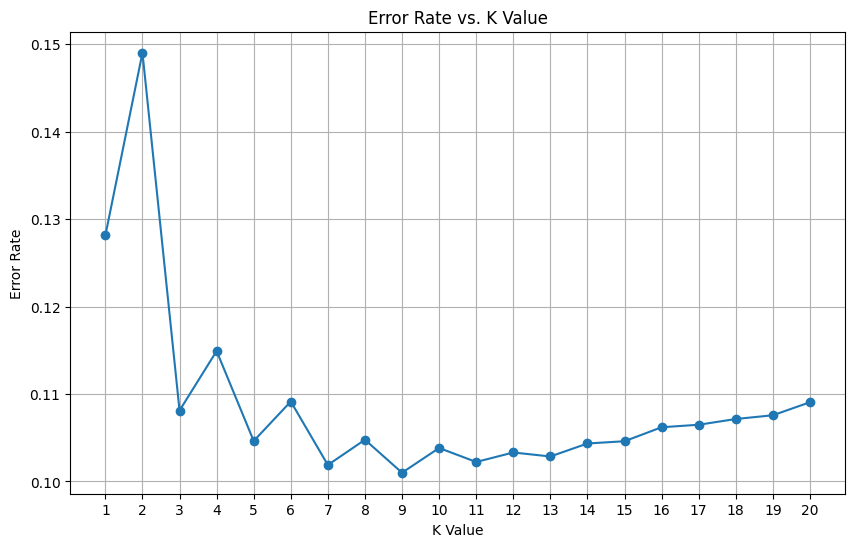

In [17]:
import matplotlib.pyplot as plt

# Calculate the error for each K
errors = []

k_values = range(1, 21)

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, train_scaled, y, cv=5)
    errors.append(1 - scores.mean())  # Classification error

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(k_values, errors, marker='o')
plt.title('Error Rate vs. K Value')
plt.xlabel('K Value')
plt.ylabel('Error Rate')
plt.xticks(k_values)
plt.grid()
plt.show()

The lowest error rate is for K = 9 value. However , it is not best choice for K since it will lead the model to overfitting. So we choose K = 15 for a more consistent model.

* # Using KNN 

In [18]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=16)

knn.fit(train_scaled,y)

pred = knn.predict(test_scaled)

print("Pred:", predictions)

output_2 = pd.DataFrame({'id': df_test.id, 'target': pred})
output_2.head()

Pred: [0 1 0 ... 0 1 2]


,id,target
0,1,1
1,2,1
2,3,0
3,4,2
4,5,1


In [19]:
output_2.to_csv('submission.csv', index=False)
print("Your submission was successfully saved!")

Your submission was successfully saved!
